<a href="https://colab.research.google.com/github/Sreehari05055/group_project/blob/main/group_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## COMP5712M: Programming for Data Science

## Group project: Data Analysis Project


# Analysing the Effect of Holidays on Walmart Sales Performance


* __Sreehari Anukumar__, _wvnp0245_@leeds.ac.uk
* _NameB_, _usernameB_@leeds.ac.uk
* _NameC_, _usernameC_@leeds.ac.uk
* _NameD_, _usernameD_@leeds.ac.uk

# Project Plan

## Description of Dataset

This project uses weekly Walmart sales from 5 February 2010 to 26 October 2012. The file contains 6,435 rows, one row for each of 45 stores in each of 143 weeks, and eight features covering sales, holiday weeks, and local conditions. The dataset was obtained from Kaggle’s Walmart weekly sales collection, which records store-level sales together with holiday and economic indicators (Yasser, 2021). 

Each row is one store in one week. `Store` is only an identity number, from 1 to 45, so the same store can be followed from week to week. `Date` is the week those sales belong to. The weeks run from 5 February 2010 to 26 October 2012. Dates are stored day-first, so `05-02-2010` is read as 5 February 2010. There are no missing values, and every store has the same 143 weeks of data.

`Weekly_Sales` is the total sales revenue for that store in that particular week, in US dollars. The quietest store-week is about \$209,986 and the busiest is about \$3,818,686, so the largest weeks are more than fifteen times the smallest. The figure is the store total for that week. It does not record individual products or departments. 

`Holiday_Flag` is 1 in a holiday week and 0 in a normal week. The holiday weeks are the Super Bowl, Labour Day, Thanksgiving, and the Christmas week. The data ends on 26 October 2012, so Thanksgiving and Christmas appear twice each, once in 2010 and once in 2011. The Super Bowl and Labour Day also appear in 2012.

`Temperature` is the outside temperature where the store is, in degrees Fahrenheit. It runs from about −2 °F to about 100 °F. `Fuel_Price` is the local fuel price in US dollars, from about \$2.47 to \$4.47. `CPI` is the consumer price index, which shows how expensive everyday goods are in that area. It runs from about 126 to 227, and a higher number means higher prices. `Unemployment` is the percentage of people out of work in that area, from about 3.9% to 14.3%.








# Project Aim & Objectives

# System Design

# Program Code

#### Objective 3: Compare each store’s holiday-week sales with its normal-week sales for the Super Bowl, Labour Day, Thanksgiving, and Christmas, and identify the stores with the largest gains and the largest losses relative to a normal week.

To achieve objective 3, `pandas`, `matplotlib.pyplot`, and `Patch` from `matplotlib.patches` were imported, as shown in the code block below.

In [20]:
# Imports required to achieve objective 

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

`filter_holidays` splits the file into holiday weeks and normal weeks. `Date` is read as a day-first date, such as `05-02-2010`. Weeks where `Holiday_Flag` is 1 are named from the month: February is the Super Bowl, September is Labour Day, November is Thanksgiving, and December is the Christmas week. The function returns those named holiday weeks, and the remaining weeks as normal weeks.

Three checks stop the function when this file is not in the expected shape. A missing `Date` or `Holiday_Flag` column raises an error. A blank or unreadable date raises an error, because every date in this file must be day-first. A holiday week outside February, September, November, or December raises an error. This file only flags the Super Bowl, Labour Day, Thanksgiving, and the Christmas week. Other holidays, for example Easter, may also occur, but they are not flagged here. A flagged week in another month would not match this dataset. These checks are written for this Walmart dataset. They would not apply to a generic dataset with different columns, date formats, or holidays.

In [21]:
def filter_holidays(df):
    """Split the weeks into named holiday weeks and normal weeks.

    February is the Super Bowl, September is Labour Day, November is
    Thanksgiving, and December is the Christmas week.
    """
    needed = {"Date", "Holiday_Flag"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Missing column: {', '.join(sorted(missing))}.")
    dates = pd.to_datetime(df["Date"], format="%d-%m-%Y", errors="coerce")
    if dates.isna().any():
        raise ValueError("A Date value could not be read. Dates must be day-first, such as 05-02-2010.")
    df["Date"] = dates
    holiday = df["Holiday_Flag"].eq(1)
    holidays = df.loc[holiday].copy()

    # 2 is February, 9 is September, 11 is November, 12 is December.
    holidays["Holiday"] = holidays["Date"].dt.month.map(
        {2: "Super Bowl", 9: "Labour Day", 11: "Thanksgiving", 12: "Christmas"}
    )
    if holidays["Holiday"].isna().any():
        raise ValueError("A holiday week is not in February, September, November, or December.")
    return holidays, df.loc[~holiday].copy()

The cell below prints the first rows of both results. The first table is the holiday weeks, and the second is the normal weeks.

In [22]:
df = pd.read_csv("Walmart_Sales.csv")
holidays, normal = filter_holidays(df)
print(holidays.head())
print(normal.head())

    Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
1       1 2010-02-12    1641957.44             1        38.51       2.548   
31      1 2010-09-10    1507460.69             1        78.69       2.565   
42      1 2010-11-26    1955624.11             1        64.52       2.735   
47      1 2010-12-31    1367320.01             1        48.43       2.943   
53      1 2011-02-11    1649614.93             1        36.39       3.022   

           CPI  Unemployment       Holiday  
1   211.242170         8.106    Super Bowl  
31  211.495190         7.787    Labour Day  
42  211.748433         7.838  Thanksgiving  
47  211.404932         7.838     Christmas  
53  212.936705         7.742    Super Bowl  
   Store       Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1 2010-02-05    1643690.90             0        42.31       2.572   
2      1 2010-02-19    1611968.17             0        39.93       2.514   
3      1 2010-02-26    1409727.59      

The `holiday_gain` function below takes the holiday weeks and the normal weeks from `filter_holidays` as input. For each store, it finds the average sales on each holiday and the average sales on that store's normal weeks. `Gain` is the holiday average minus the normal-week average. A positive gain means the holiday week sold more than a normal week. A negative gain means it sold less, which is a loss of sales relative to a normal week. 

In [23]:
def holiday_gain(holidays, normal):
    """Gain for each store on each holiday.

    Gain is that store's average sales on the holiday minus the same store's
    average sales on normal weeks. A positive gain means the holiday week sold
    more than a normal week. A negative gain means it sold less.
    """
    holiday_avg = holidays.groupby(["Store", "Holiday"], as_index=False)["Weekly_Sales"].mean()
    normal_avg = normal.groupby("Store", as_index=False)["Weekly_Sales"].mean()
    holiday_avg = holiday_avg.rename(columns={"Weekly_Sales": "Holiday_Avg"})
    normal_avg = normal_avg.rename(columns={"Weekly_Sales": "Normal_Avg"})
    gain = holiday_avg.merge(normal_avg, on="Store")
    # Gain is the holiday week minus that store's normal week.
    gain["Gain"] = gain["Holiday_Avg"] - gain["Normal_Avg"]
    return gain

The `plot_ranked_gains` function draws a horizontal bar chart with four panels, one each for the Super Bowl, Labour Day, Thanksgiving, and Christmas. For each holiday it keeps the 10 stores with the highest gain, in blue, and the 10 with the lowest gain, in red. The gain is shown in thousands of dollars. The function is called in Results Overview, where the chart is discussed.

In [24]:
def plot_ranked_gains(gain):
    """Bar chart of store gains for each holiday.

    One panel each for the Super Bowl, Labour Day, Thanksgiving, and Christmas.
    Blue bars are the 10 stores with the highest gain. Red bars are the 10
    stores with the lowest gain. The other stores are left out.
    """
    
    holidays = ("Super Bowl", "Labour Day", "Thanksgiving", "Christmas")
    fig, axes = plt.subplots(2, 2, figsize=(13, 11), layout="constrained")
    for ax, holiday in zip(axes.ravel(), holidays):
        part = gain.loc[gain["Holiday"].eq(holiday)].sort_values("Gain")
        if part.empty:
            raise ValueError(f"No rows for {holiday}, so the chart cannot be drawn.")
        show = pd.concat([part.head(10), part.tail(10)])
        
        # Divide by 1000 so the axis is in thousands of dollars.
        ax.barh(show["Store"].astype(str), show["Gain"] / 1000, color=["#c44e52"] * 10 + ["#4c72b0"] * 10)
        
        ax.axvline(0, color="black", linewidth=0.8)
        ax.set_title(holiday)
        ax.set_xlabel("Gain ($ thousands)")
        ax.set_ylabel("Store")
        ax.tick_params(axis="y", labelsize=8)
    fig.legend(handles=[
        Patch(color="#4c72b0", label="Top 10"),
        Patch(color="#c44e52", label="Bottom 10"),
    ], loc="outside lower center", ncol=2)
    fig.suptitle("Top 10 and bottom 10 stores by holiday gain")
    return fig

The output of `holiday_gain` is shown below. A negative gain is a loss of sales compared with that store's average normal week. A positive gain means the holiday week sold more than that normal week.

In [25]:
gain = holiday_gain(holidays, normal)
print(gain)

     Store       Holiday   Holiday_Avg    Normal_Avg           Gain
0        1     Christmas  1.432391e+06  1.546957e+06 -114566.020639
1        1    Labour Day  1.569900e+06  1.546957e+06   22942.367694
2        1    Super Bowl  1.698017e+06  1.546957e+06  151059.214361
3        1  Thanksgiving  1.994472e+06  1.546957e+06  447514.999361
4        2     Christmas  1.812331e+06  1.914209e+06 -101878.276880
..     ...           ...           ...           ...            ...
175     44  Thanksgiving  3.083878e+05  3.032536e+05    5134.132218
176     45     Christmas  7.742799e+05  7.821985e+05   -7918.613496
177     45    Labour Day  7.447008e+05  7.821985e+05  -37497.715163
178     45    Super Bowl  7.423673e+05  7.821985e+05  -39831.275163
179     45  Thanksgiving  1.176587e+06  7.821985e+05  394388.021504

[180 rows x 5 columns]


The `main` function block runs objective 3 from start to finish. It reads `Walmart_Sales.csv`, passes the table to `filter_holidays`, and passes those two results to `holiday_gain`. It then prints the gain table.

Before that, three checks protect the load. If `Walmart_Sales.csv` is not in the current folder, the function raises an error. If the file is empty, it raises an error. If `Store` or `Weekly_Sales` is missing, it raises an error. Those two columns are required by this dataset, so this column check would not apply to a generic file.

In [26]:
def main():
    """Main method of objective 3.

    Finds which stores gain the most sales on Thanksgiving, Christmas, Labour Day,
    and the Super Bowl, and which barely move.
    """
    try:
        df = pd.read_csv("Walmart_Sales.csv")
    except FileNotFoundError:
        raise FileNotFoundError("Walmart_Sales.csv was not found in the current folder.") from None
    except pd.errors.EmptyDataError:
        raise ValueError("Walmart_Sales.csv is empty.") from None
    needed = {"Store", "Weekly_Sales"}
    missing = needed - set(df.columns)
    if missing:
        raise ValueError(f"Missing column: {', '.join(sorted(missing))}.")

    holidays, normal = filter_holidays(df)
    gain = holiday_gain(holidays, normal)
    
    print(gain)

if __name__ == '__main__':
    main()

     Store       Holiday   Holiday_Avg    Normal_Avg           Gain
0        1     Christmas  1.432391e+06  1.546957e+06 -114566.020639
1        1    Labour Day  1.569900e+06  1.546957e+06   22942.367694
2        1    Super Bowl  1.698017e+06  1.546957e+06  151059.214361
3        1  Thanksgiving  1.994472e+06  1.546957e+06  447514.999361
4        2     Christmas  1.812331e+06  1.914209e+06 -101878.276880
..     ...           ...           ...           ...            ...
175     44  Thanksgiving  3.083878e+05  3.032536e+05    5134.132218
176     45     Christmas  7.742799e+05  7.821985e+05   -7918.613496
177     45    Labour Day  7.447008e+05  7.821985e+05  -37497.715163
178     45    Super Bowl  7.423673e+05  7.821985e+05  -39831.275163
179     45  Thanksgiving  1.176587e+06  7.821985e+05  394388.021504

[180 rows x 5 columns]


# Results Overview

### Objective 3

#### Explanation of Results

The horizontal bar chart below shows, for each holiday, the 10 stores with the highest gain and the 10 with the lowest. Gain is that store's holiday-week average minus its normal-week average.

Objective 3 compares each store's holiday-week sales with its own normal-week sales for the Super Bowl, Labour Day, Thanksgiving, and Christmas, and identifies the stores with the largest gains and the largest losses relative to a normal week.

The chart keeps the 10 highest gains in blue and the 10 lowest in red. The axis is in thousands of dollars. A positive bar is higher sales than that store's normal week. A negative bar is a loss of sales relative to that normal week, not a loss in the accounts.

Thanksgiving shows the largest gains. Store 10 is the highest, about \$1.06 million above its normal week. Only four stores in the whole set are below a normal week on Thanksgiving, and the largest of those falls is about \$12,000 at store 33. Most of the red bars are still above zero, so even the lowest Thanksgiving weeks are close to a normal week or only slightly below it.

The Super Bowl also lifts sales, but by less. Store 10 is again the highest, at about \$287,000 above its normal week. Twelve stores are below a normal week. Store 39 is the lowest, at about \$131,000 below.

Labour Day is mixed. Store 17 has the highest gain, about \$319,000. Store 10, which gains the most at Thanksgiving and the Super Bowl, has the lowest Labour Day result, about \$184,000 below its normal week. Twenty-six stores are below a normal week.

Christmas is the weakest of the four holidays in this file. Forty-one of the 45 stores are below a normal week. Store 7 is the highest, at about \$210,000 above its normal week, and store 14 is the lowest, at about \$245,000 below. The largest fall is bigger than the largest gain. The Christmas flag is the week ending 31 December 2010 and 30 December 2011, the week after the main shopping week.

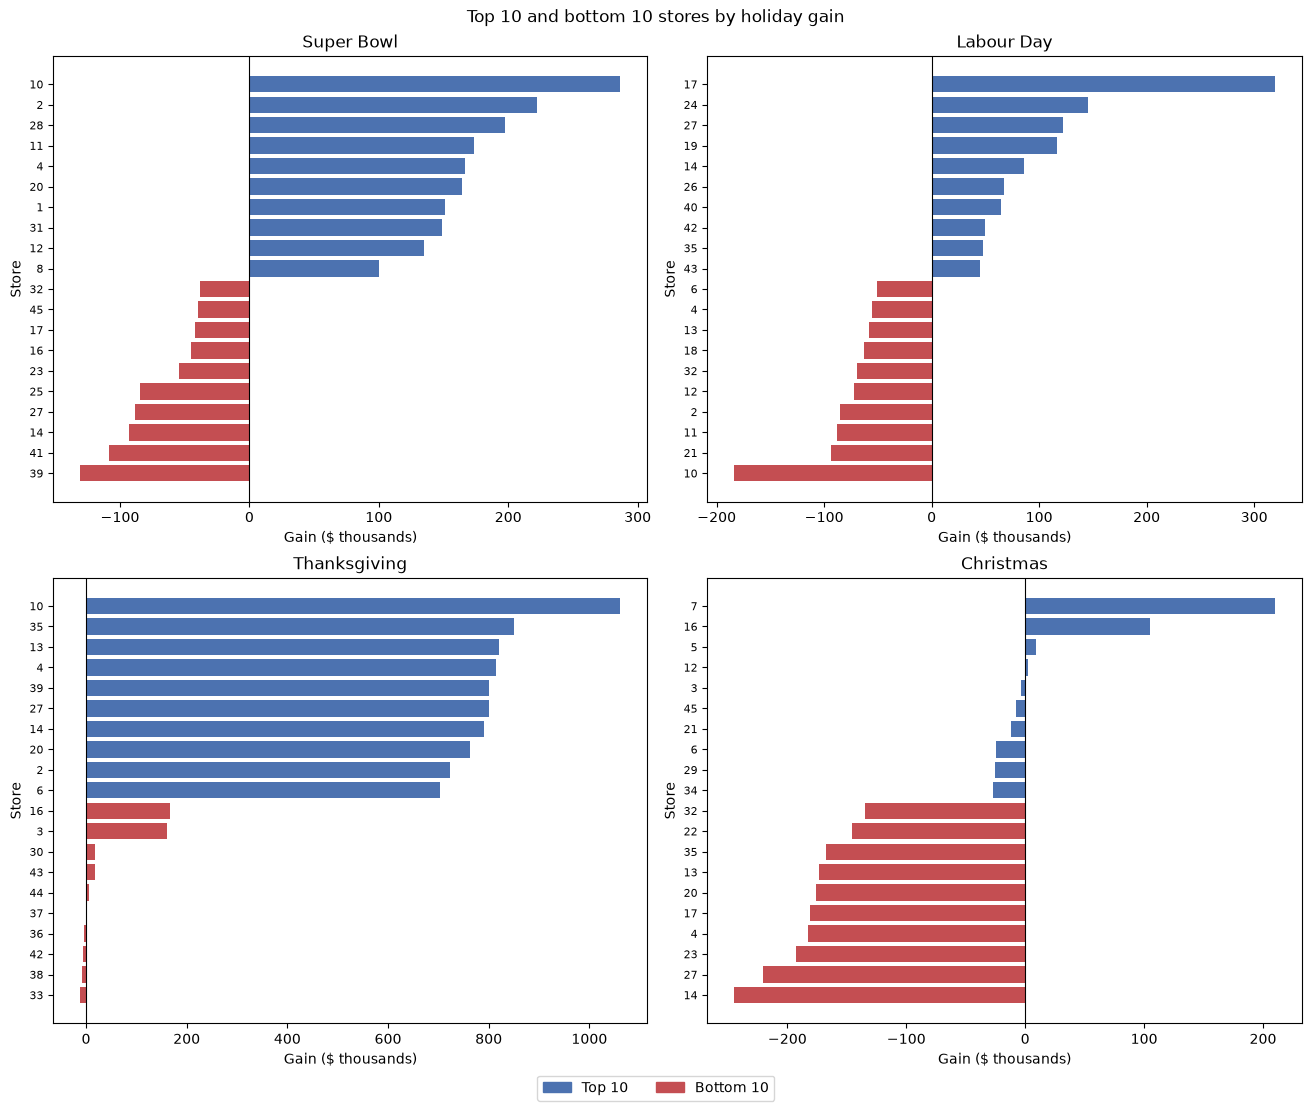

In [40]:
plot_ranked_gains(gain);

# Project Requirements
_PLEASE DELETE THIS WHOLE CELL BEFORE SUBMITTING YOUR PROJECT_

The purpose of this assignment is to develop your skills
in organising and presenting a data analysis project.

Since most of the marks will be awarded for organisation
and presentation, it is suggested that you do not initially attempt
anything too complicated. However, once you have managed
to get a basic pipeline working that fits the guidelines,
you are encouraged to extend and elaborate your analysis.

Your project should entirely be contained within this template file.
You should keep the basic structure indicated below. To facilitate
grading according to the marking scheme.

You _may_ import any module.


### Marking Scheme

The marking scheme  is as follows:

* Project Plan:
    * Description of data to be used (10)
    * Overview of Project Aims  (5)
    * Design  (5)
    
* Program Code: (15)<br>
    Code should be laid out in steps with explanations
    and intermediate output with comments.
    You should ensure that the steps do not require
    a large amount of processing time.

* Project Outcome:
    * Explanation of Results (10)<br>
        This should include a qualitative description
        of the results as well as key figures and tables
        of results.
    * Results visualisation (10)<br>
        This should be graphical representations of the
        results with brief explanations (ordinary tables will be
        graded as part of the explanation of results)
    * Conclusion (5)
*Reflection:


### Data Resources

You can use any data you like. Many useful resources are available.

As a starting point you could browse the following:
* [Kaggle](https://www.kaggle.com/)
* [Our World in Data](https://ourworldindata.org/)
* [scikit-learn datasets](https://scikit-learn.org/stable/datasets.html)
* [scikit-learn tutorial](https://scikit-learn.org/stable/tutorial/basic/tutorial.html)




### Using this Notebook Template
Please use this notebook as a template for your project file.
In the following cells of the notebook, _italic text_ giving explanations
and examples should be either deleted, or, in most cases, replaced by appropriate text describing your project.
Text that is not in italic (which is mostly headings) should
be left as it is. __Your project report notebook should have the same overall
structure as this template notebook.__
An exception to this is the current markup cell describing the project
requiements. You should delete this before submitting your notebook.

# Project Plan

## The Data (10 marks)

_Here you should describe the data including details of:
where it comes from, what data it contains, is it accurate. (Potentially you could create data from a simulation but you should still explain why and how you intend to generate this data.)_

_It can be just one dataset or several that can be combined
logically. To ensure sufficient depth for analysis, the final dataset must contain a mininum of 1000 rows and 7 features._

_There are 10 marks for this, so a fairly detailed description
of the data is expected. You should include details including the size, the features, range of values, and so on._



## Project Aim and Objectives (5 marks)

_Here you should describe the general aim of your project in
around 200-300 words._

_This can can be anything from classifying items according to
their characteristic features (which mushrooms are poisonous?)
to simulating an evolving process (will the rabbits eat all
the carrots or get eaten by the foxes?)_

_Here some ideas of general types of processing functionality
that you could implement:_

* _Classification: separate data items into classes according
  to their charactersitics (can be either a definite or a
  statistical kind of classification)_
* _Corellation: find correspondences between different attributes within
  a dataset_
* _Search: find solutions matching some criteria_
* _Visualisation: find informative ways to
  display the structure of a large and/or complex dataset useful for decision making_
* _Query Answering: create a system that enables one to retrieve information by evaluating some form of query representation_
* _Simulation: model the evolution of a complex process_

### Specific Objective(s)

_You should chose and list __up to 4__ specific objectives suited to the data you will be working with and the type of project you wish to carry out according to the project aim.
There should be <b>at least one
per person doing the project</b>. There is no need
for  the objectives them to be completely different.
They could be different
stages of the processing requirements, or different processing
functions that the system  provides. Or just
different aspects of data analysis that will be conducted.
Typically, it is expected that there would be one objective
per person. Replace the following examples with your own objectives:_

* __Objective 1:__ _create a Python datastructure that will ensure world peace_
* __Objective 2:__ _stop global warming using a pandas dataframe_
* __Objective 3:__ _end poverty using matplotlib_
* __Objective 4:__ _end suffering with sklearn_

## System Design (5 marks)

_Describe your code in terms of the
following two sections._

### Architecture

_Typically this would be  a pipeline in which __data__ goes through several
stages of transformation and analysis, but other architectures are possible.
This does not need to be particularly complicated. A simple diagram with
100-150 words of explanation would
be a good way to present your architecture._
  
### Processing Modules and Algorithms

_Briefly list and describe the most significant computational components of your system and the algorithms you will use to implement them.
This could include things like:_

* _cleaning the data by removing outliers_
* _combining different datasets_
* _converting samples to a special representation (such as feature vectors)_
* _constructing a special data-structure (such as a decision tree)_
* _running some kind of analysis_

_Your list can be presented in similar form to the one just given,
but should include a brief
but more specific description of the components and/or algorithms.
Probably three or four components is sufficient for most projects, but
you may want to have more._

# Program Code (15 marks)

_Your code should be divided into relatively short cells, with brief
explanation in markup cells between._

_As noted in the assignment overview, it is not necessary that your coding be
super complex in order to get a good mark. Although there is a mark for
the coding achievement, it is only a quarter of the total._

_The suggested length of the code is about 150 lines for 1 person or 500
for a 4 people project. You should not use more than 500 lines of code._

_You should divide the code in accordance with the specification of modules and/or
algorithms you gave in the previous section. Complex modules should be further
divided into several code cells._

Please note the following about your code:
* <b><i>You may import any packages/modules you wish to use for your project.</i></b> However, for special packages/modules, it would be nice to put comments or a sentence on where these modules are used in the project.


* <b><i>You should submit your notebook in a state where all cells have been
    executed and are displaying the output that you wish to present for grading.</i></b>
    (We will not normally run your code, unless for some reason we wish to check
    that the code functionality matches the given description.)
    
    
* It is strongly suggested you use __function definitions to organise your code__. As well as being generally good programming practice, it will be helpful for easy and flexibily presentation of results visualisations later in the document. In the visualisation sections you will be able to produce images in a concise and flexible way by calling functions defined in the program code secion.

#### _Brief Explanation of following code cell_

_Below is a silly example of some trivial data. Replace this markup cell and the one below with something more interesting. And go on adding more until you have
achieved your objectives (at least to some extent)._

In [36]:
## Code Cell
## This will typically consist of:

## (a) Code doing some data manipulation:

fm_data = { "souvenir"     :  9,
            "cute animal"  :  5,
            "meme"         : 36,
            "smiley"       :  3,
            "random image" : 13
          }
total = sum([fm_data[f] for f in fm_data])

## (b) Code for displaying some output:

print("The total number of fridge magnets is:", total)

The total number of fridge magnets is: 66


#### _Comment on previous cell output (optional)_

_As well as describing code, it will in many cases be informative to describe the output
that has been generated by a cell._

_The previous output cell shows a key number in our fridge magnet analysis._

#### _Brief Explanation of following code cell_

_Since fridge magnets often take the form of cute animals, we use `pandas` to convert the raw data into a `DataFrame`._

In [37]:
## Code Cell
import pandas
df = pandas.DataFrame.from_dict(fm_data, orient='index')
df

,0
souvenir,9
cute animal,5
meme,36
smiley,3
random image,13


#### _Comment on previous cell output (optional)_
_The output from the previous cell is very interesting._

_The following cell defines a visualisation function for the data._

In [38]:
def fridge_sorted_bar(color='blue'):
    df.sort_values(0).plot.bar( color=color)

###  _More code cells_
_You can add as many code cells as you require, but it is
recommended that you break code into relatively small chunks and
do not exceed the maximum number of lines stated above._

# Project Outcome (10 + 10 marks)

_This section should describe the outcome of the project by means of both explanation of the results and by graphical visualisation in the form of graphs, charts or or other kinds of diagram_

_The section should begin with a general overview of the results and then have a section for each of the project objectives. For each of these objectives an explanation of more specific results relating to that objective shoud be given, followed by a section presenting some visualisation of the results obtained. (In the case where
the project had just one objective, you should still have a section describing
the results from a general perspective followed by a section that focuses on
the particular objective.)_

_The marks for this section will be divided into 10 marks for Explanation
and 10 marks for Visualisation. These marks will be awarded for the Project Outcome
section as a whole, not for each objective individually. Hence, you do not
have to pay equal attention to each. However, you are expected to have a
some explanation and visualisation for each. It is suggested you have
200-400 words explanation for each objective._

## Overview of Results
_Give a general overview of the results (around 200 words)._

## Objective 1

### Explanation of Results

_200-400 words_

### Visualisation
_The following bar chart gives a vivid representation of the distribution
of fridge magnet types, in which the dominance of 'meme' type magnets
is dramatically illustrated._

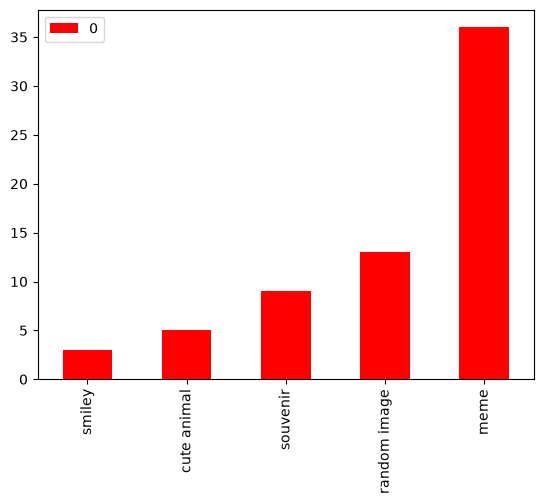

In [39]:
fridge_sorted_bar(color='red')

## Objective 2
### Explanation of Results

200-400 Words

### Visualisation

## Objective 3
### Explanation of Results

200-400 Words

### Visualisation

## Objective 4
### Explanation of Results

200-400 Words

### Visualisation

# Conclusion (5 marks)

_Your concluding section should be around 200-400 words. It is recommended
that you divide it into the following sections._

### Achievements
_As we had expected, the most popular fridge magnets were of the 'meme' kind.
We were surprised that 'smiley' fridge magnets were less common than expected.
We conjecture that this is because, although they are apparently very popular,
few fridges display more than one smiley. However, 'meme' based magnets can
be found in large numbers, even on quite small fridges._

### Limitations

_The project was limited to a small number of fridge magents, which may not be
typical of fridges found in the global fridge magnet ecosystem._

### Future Work

_In future work we would like to obtain more diverse data and study fridge magnets
beyond the limited confines of student accomodation. We hypothesise that there
could be a link between fridge magnet types and social class and/or educational
achievement._

# References

Yasser, H. (2021) Walmart Dataset. Kaggle. Available at: https://www.kaggle.com/datasets/yasserh/walmart-dataset (Accessed: 10 November 2026).